In [2]:
# This block imports and sets up all dataframes and libraries

import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Reads csv files and converts date/time columns to datetime format
scan_df = pd.read_csv('raw_data/scan_pred_data.csv', usecols=['DateTime', 'ag250', 'predicted_DOC'])
scan_df['DateTime'] = pd.to_datetime(scan_df['DateTime'])
scan_df['DateTime'] = scan_df['DateTime'].dt.tz_localize('UTC')

precip_df = pd.read_csv('raw_data/HF_AIRTEMP_PRECIP_DAILY.csv', usecols=['date','prec'])
precip_df['date'] = pd.to_datetime(precip_df['date'])

discharge_df = pd.read_csv('raw_data/HF_DISCHARGE_WATERTEMP_15MIN.csv',usecols=['datetime','nt.dis', 'al.dis', 'au.dis'])
discharge_df['datetime'] = pd.to_datetime(discharge_df['datetime'])
discharge_df['datetime'] = discharge_df['datetime'].dt.tz_localize('UTC')

water_temp_df = pd.read_csv('raw_data/HF_DISCHARGE_WATERTEMP_15MIN.csv', usecols=['datetime', 'nb.wt', 'al.wt', 'au.wt'])
water_temp_df['datetime'] = pd.to_datetime(water_temp_df['datetime'])
water_temp_df['datetime'] = water_temp_df['datetime'].dt.tz_localize('UTC')

# Filter dates
start_date = '2023-10-01'
end_date = '2025-07-01'

scan_data = scan_df.loc[(scan_df['DateTime'] >= start_date) & (scan_df['DateTime'] <= end_date)]
precip_data = precip_df.loc[(precip_df['date'] >= start_date) & (precip_df['date'] <= end_date)]
discharge_data = discharge_df.loc[(discharge_df['datetime'] >= start_date) & (discharge_df['datetime'] <= end_date)]
water_temp_data = water_temp_df.loc[(water_temp_df['datetime'] >= start_date) & (water_temp_df['datetime'] <= end_date)]


C:\Users\sends\AppData\Local\Temp\ipykernel_35628\3622736131.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  scan_df['DateTime'] = pd.to_datetime(scan_df['DateTime'])


Text(0.5, 1.0, 'Precipitation and Predicted DOC Time Series')

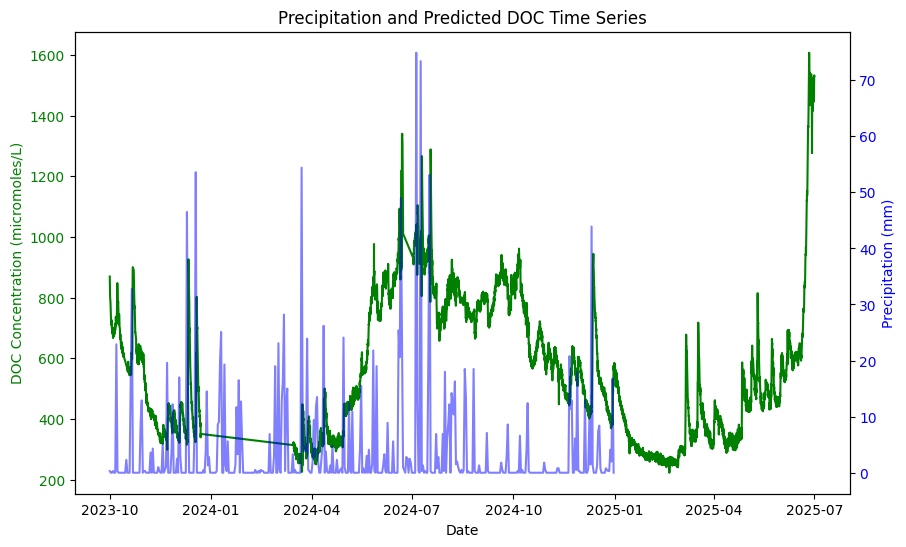

In [2]:
# PLOTS DOC CONCENTRATION AND PRECIPITATION TIME SERIES

# Establishes figure and common x-axis
fig, ax1 = plt.subplots(figsize=(10,6))

# plots predicted_DOC on left y-axis
ax1.plot(scan_data['DateTime'], scan_data['predicted_DOC'], color='green', label='predicted_DOC')
ax1.set_xlabel('Date')
ax1.set_ylabel('DOC Concentration (micromoles/L)', color='green')
ax1.tick_params(axis='y', labelcolor='green')

# creates second y-axis
ax2 = ax1.twinx()

# plots precipitation on right y-axis
ax2.plot(precip_data['date'], precip_data['prec'], color='blue', label='Precipitation', alpha=0.5)
ax2.set_ylabel('Precipitation (mm)', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

plt.title('Precipitation and Predicted DOC Time Series')

In [1]:
# DISCHARGE VS DOC

# Plots a stacked bar chart + time series of DOC concentration

# fig, ax1 = plt.subplots(figsize=(12, 6))

column_list = ['al.dis', 'au.dis', 'nt.dis']
label_list = ['Arthur Lower', 'Arthur Upper', 'Nelson Total']
color_list = ['yellow', 'orange', 'red']
# bottom = 0

# for i, col in enumerate(column_list):
#     ax1.bar(discharge_data['datetime'], discharge_data[col], width=0.5, bottom=bottom, 
#             label=label_list[i], color=color_list[i], alpha=0.6)
#     bottom += discharge_data[col] # Stacks each bar on top of the next

# ax1.legend(title='Sites',loc='upper right')

# ax1.set_xlabel('Time')
# ax1.set_ylabel('Discharge (L/s)')
# ax1.tick_params(axis='y', labelcolor='red')

# ax2 = ax1.twinx()

# ax2.plot(scan_data['DateTime'], scan_data['predicted_DOC'], color='black', label='predicted_DOC')
# ax2.set_ylabel('DOC Concentration (micromoles/L)')
# ax2.tick_params(axis='y', labelcolor='black')

# plt.title('Discharge and Predicted DOC Time Series')
# plt.show()

# Stackplot version

fig2, ax3 = plt.subplots(figsize=(12,6))

ax3.stackplot(discharge_data['datetime'], discharge_data['al.dis'], discharge_data['au.dis'], discharge_data['nt.dis'],
              labels=label_list, colors=color_list, alpha=0.5)
ax3.set_ylabel('Stream Discharge (L/s)')
# ax3.set_ylim(0, 10) # sets the scale of the axis
ax3.tick_params(axis='y', labelcolor='black')

ax3.legend(loc='upper right')

ax4 = ax3.twinx()

ax4.plot(scan_data['DateTime'], scan_data['predicted_DOC'], color='green', label='predicted_DOC')
ax4.set_ylabel('DOC Concentration (micromoles/L)')
ax4.tick_params(axis='y', labelcolor='green')

# Example formatting
# ax3.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax3.xaxis.get_major_locator()))

# Cooler formatting
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d')) # Learn the formatting methods lol

for label in ax3.get_xticklabels(which='major'):
    label.set(rotation=30, horizontalalignment='right')

plt.title('Stream Discharge and DOC Concentration Time Series')



NameError: name 'plt' is not defined

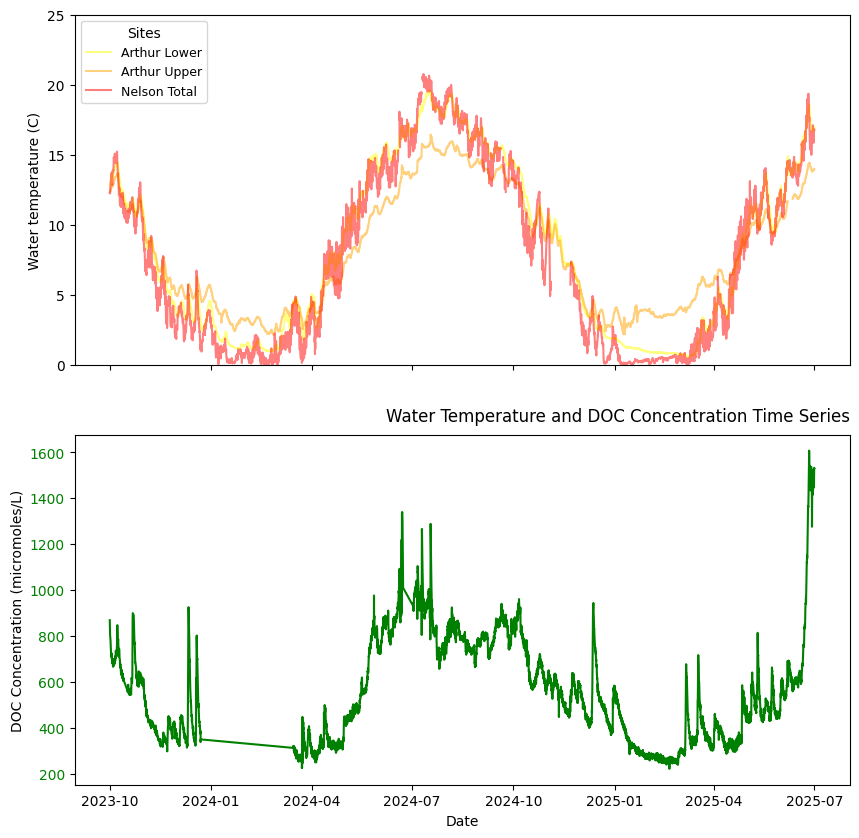

In [4]:
# WATER TEMPERATURE VS DOC - multiline plot

# Multiline plot with pandas

# water_temp_data = water_temp_data.set_index('datetime')

# ax1 = water_temp_data.plot(figsize=(10,6), alpha=0.7)

# ax1.set_xlabel('Date')
# ax1.set_ylabel('Water temperature (C)')

# ax1.legend(labels=['Nelson Big Weir', 'Arthur Upper', 'Arthur Lower'], title='Sites', loc='upper left', fontsize=10)

# ax2 = ax1.twinx()

# ax2.plot(scan_data['DateTime'], scan_data['predicted_DOC'], color='red', label='predicted_DOC')
# ax2.set_ylabel('DOC Concentration (micromoles/L)')
# ax2.tick_params(axis='y', labelcolor='red')

# plt.title('Stream Temperature vs Predicted DOC')
# plt.show()   

# Matplotlib version

column_list = ['al.wt', 'au.wt', 'nb.wt']
label_list = ['Arthur Lower', 'Arthur Upper', 'Nelson Total']
color_list = ['yellow', 'orange', 'red']

fig, (ax3, ax4) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

index = water_temp_data['datetime']

for i, col in enumerate(column_list):
    ax3.plot(index, water_temp_data[col], label=label_list[i], color=color_list[i], alpha=0.5)

ax3.set_ylabel('Water temperature (C)')
ax3.set_ylim(0, 25)
ax3.tick_params(axis='y', labelcolor='black')

ax3.legend(title='Sites', loc='upper left', fontsize=9)

ax4.plot(scan_data['DateTime'], scan_data['predicted_DOC'], color='green', label='predicted_DOC')
ax4.set_xlabel('Date')
ax4.set_ylabel('DOC Concentration (micromoles/L)')
ax4.tick_params(axis='y', labelcolor='green') 

plt.title('Water Temperature and DOC Concentration Time Series', pad=10, loc='right')
plt.show()